In [1]:
import torch

print(torch.__version__)

2.14.1+cpu


In [2]:
from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor

c:\Zahra\projects\weather-shift-segmentation-2026\weather-shift-segmentation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
name = "nvidia/segformer-b0-finetuned-cityscapes-1024-1024"
processor = SegformerImageProcessor.from_pretrained(name)
model = SegformerForSemanticSegmentation.from_pretrained(name)
model.eval()

Loading weights: 100%|██████████| 208/208 [00:00<00:00, 24383.44it/s]


SegformerForSemanticSegmentation(
  (segformer): SegformerModel(
    (stages): ModuleList(
      (0): SegformerStage(
        (patch_embeddings): SegformerOverlapPatchEmbeddings(
          (proj): Conv2d(3, 32, kernel_size=(7, 7), stride=(4, 4), padding=(3, 3))
          (layer_norm): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        )
        (blocks): ModuleList(
          (0): SegformerLayer(
            (layernorm_before): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
            (attention): SegformerAttention(
              (q_proj): Linear(in_features=32, out_features=32, bias=True)
              (k_proj): Linear(in_features=32, out_features=32, bias=True)
              (v_proj): Linear(in_features=32, out_features=32, bias=True)
              (o_proj): Linear(in_features=32, out_features=32, bias=True)
              (sequence_reduction): SegformerSequenceReduction(
                (sequence_reduction): Conv2d(32, 32, kernel_size=(8, 8), s

In [4]:
model.config.id2label

{0: 'road',
 1: 'sidewalk',
 2: 'building',
 3: 'wall',
 4: 'fence',
 5: 'pole',
 6: 'traffic light',
 7: 'traffic sign',
 8: 'vegetation',
 9: 'terrain',
 10: 'sky',
 11: 'person',
 12: 'rider',
 13: 'car',
 14: 'truck',
 15: 'bus',
 16: 'train',
 17: 'motorcycle',
 18: 'bicycle'}

In [5]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

Total parameters: 3,719,027


In [6]:
print(processor)

SegformerImageProcessor {
  "do_normalize": true,
  "do_reduce_labels": false,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.485,
    0.456,
    0.406
  ],
  "image_processor_type": "SegformerImageProcessor",
  "image_std": [
    0.229,
    0.224,
    0.225
  ],
  "reduce_labels": false,
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 512,
    "width": 512
  }
}



In [7]:
print(f"Image size: {processor.size}")
print(f"Image mean: {processor.image_mean}")
print(f"Image std: {processor.image_std}")

Image size: SizeDict(height=512, width=512, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
Image mean: (0.485, 0.456, 0.406)
Image std: (0.229, 0.224, 0.225)


In [8]:
import numpy as np
from matplotlib import pyplot as plt
from PIL import Image

In [9]:
image = Image.open("../data/samples/street1.jpg").convert("RGB")

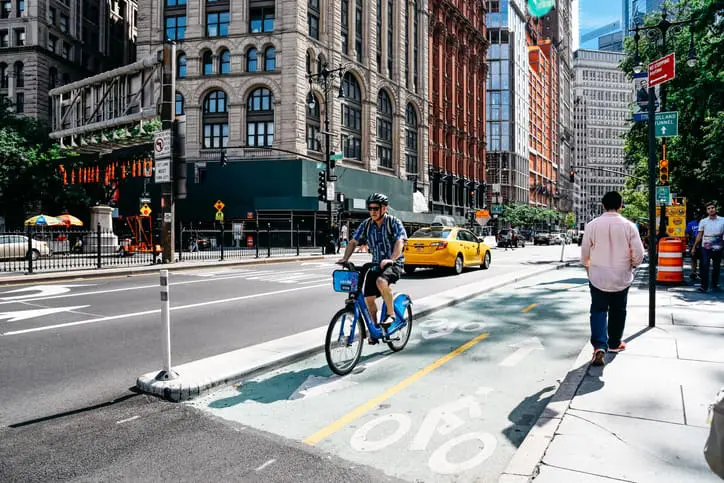

In [10]:
display(image)

In [11]:
# The processor resizes, rescales, and normalizes the image, then converts it into a PyTorch tensor.

inputs = processor(images=image, return_tensors="pt")
print(f"Input shape: {inputs['pixel_values'].shape}")

Input shape: torch.Size([1, 3, 512, 512])


In [12]:
# The model produces a score for each of the 19 possible classes
# at every location in its output grid.

with torch.no_grad():
    outputs = model(**inputs)

In [13]:
# 1 image, 19 possible classes, 128 × 128 output grid
outputs.logits.shape 

torch.Size([1, 19, 128, 128])

In [14]:
W, H = image.size

In [15]:
# interpolate() resizes the class-score maps to the original image dimensions (H, W).
resized = torch.nn.functional.interpolate(
    outputs.logits, size=(H, W), mode="bilinear", align_corners=False
)

# argmax returns the class ID with the highest score (0, 1, ...),
# not the score itself.
mask = resized.argmax(dim=1)[0]

In [16]:
# It returns the unique class IDs present in the predicted segmentation mask.
torch.unique(mask)

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8, 10, 11, 12, 13, 18])

In [17]:
for label_id in torch.unique(mask):
    label_name = model.config.id2label[label_id.item()]
    print(f"label_id: {label_id.item()}, label_name: {label_name}")

label_id: 0, label_name: road
label_id: 1, label_name: sidewalk
label_id: 2, label_name: building
label_id: 3, label_name: wall
label_id: 4, label_name: fence
label_id: 5, label_name: pole
label_id: 6, label_name: traffic light
label_id: 7, label_name: traffic sign
label_id: 8, label_name: vegetation
label_id: 10, label_name: sky
label_id: 11, label_name: person
label_id: 12, label_name: rider
label_id: 13, label_name: car
label_id: 18, label_name: bicycle


In [18]:
mask

tensor([[2, 2, 2,  ..., 8, 8, 8],
        [2, 2, 2,  ..., 8, 8, 8],
        [2, 2, 2,  ..., 8, 8, 8],
        ...,
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0]])

In [19]:
# Create a color palette for the segmentation mask visualization.
palette = np.array([
    [128, 64, 128],   # 0 - road
    [244, 35, 232],   # 1 - sidewalk
    [70, 70, 70],     # 2 - building
    [102, 102, 156],  # 3 - wall
    [190, 153, 153],  # 4 - fence
    [153, 153, 153],  # 5 - pole
    [250, 170, 30],   # 6 - traffic light
    [220, 220, 0],    # 7 - traffic sign
    [107, 142, 35],   # 8 - vegetation
    [152, 251, 152],  # 9 - terrain
    [70, 130, 180],   # 10 - sky
    [220, 20, 60],    # 11 - person
    [255, 0, 0],      # 12 - rider
    [0, 0, 142],      # 13 - car
    [0, 0, 70],       # 14 - truck
    [0, 60, 100],     # 15 - bus
    [0, 80, 100],     # 16 - train
    [0, 0, 230],      # 17 - motorcycle
    [119, 11, 32]    # 18 - bicycle
], dtype=np.uint8)

palette.shape

(19, 3)

In [20]:
color_image = palette[mask.numpy()]

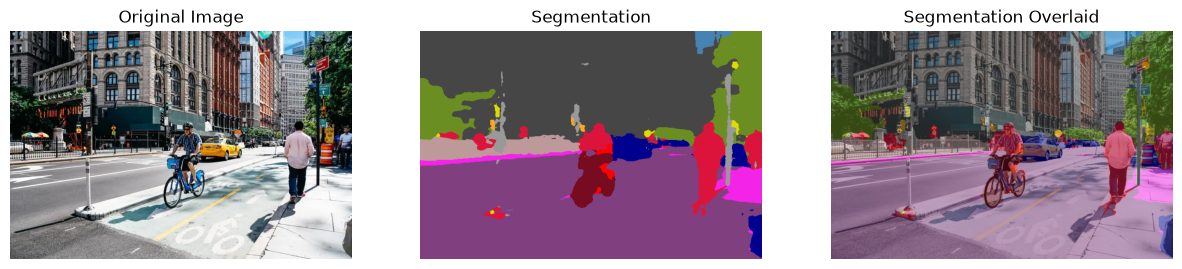

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(15, 10))

# Display the original image
ax[0].imshow(image)
ax[0].set_title("Original Image")

# Display the segmentation mask
ax[1].imshow(color_image)
ax[1].set_title("Segmentation")

# Display the segmentation mask overlaid on the original image
ax[2].imshow(image)
ax[2].imshow(color_image, alpha=0.5)
ax[2].set_title("Segmentation Overlaid")

for a in ax:
    a.axis("off")

plt.show()

In [22]:
# Compute the probabilities for each class
probs = torch.softmax(resized, dim=1)

# Take the highest probability per pixel which shows the model's confidence in its predictions
conf = probs.max(dim=1).values[0]

In [23]:
conf.mean()

tensor(0.9046)

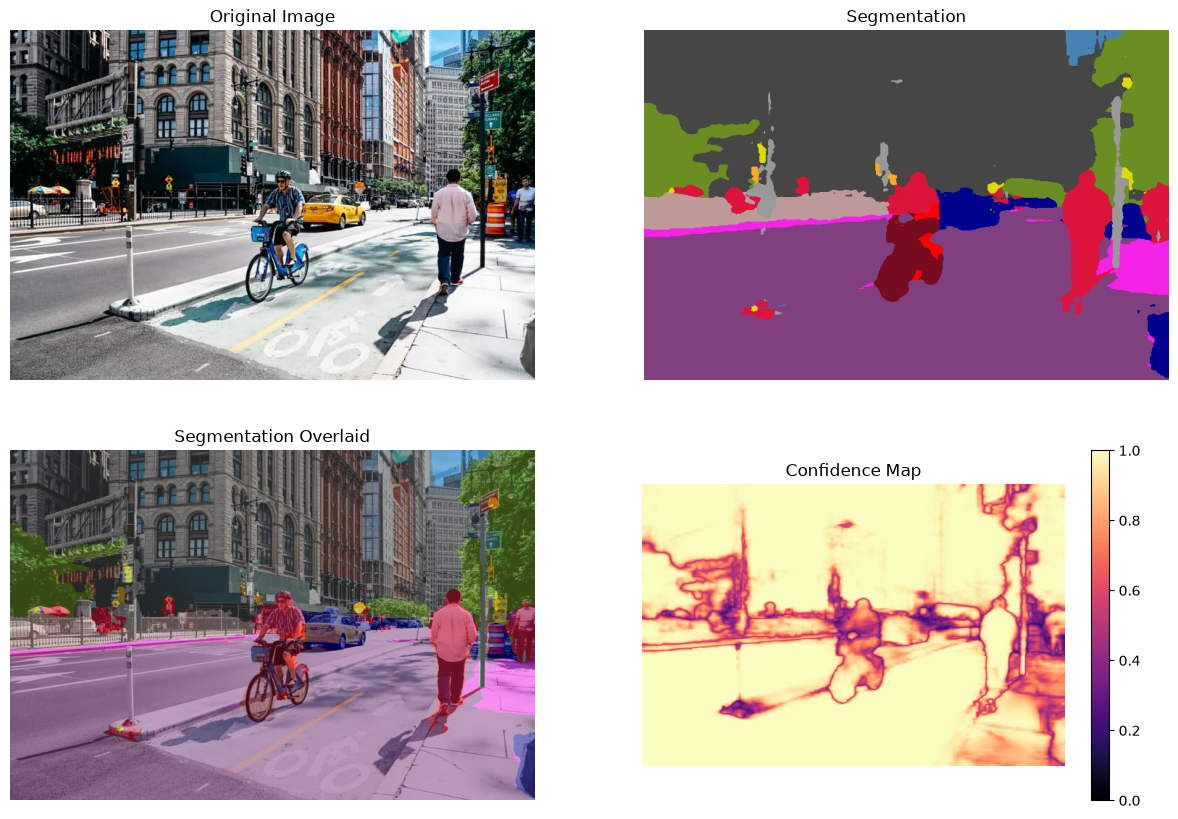

In [24]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# Display the original image
ax[0][0].imshow(image)
ax[0][0].set_title("Original Image")

# Display the segmentation mask
ax[0][1].imshow(color_image)
ax[0][1].set_title("Segmentation")

# Display the segmentation mask overlaid on the original image
ax[1][0].imshow(image)
ax[1][0].imshow(color_image, alpha=0.5)
ax[1][0].set_title("Segmentation Overlaid")

# Display the confidence map
im = ax[1][1].imshow(conf, cmap="magma", vmin=0, vmax=1)
ax[1][1].set_title("Confidence Map")
fig.colorbar(im, ax=ax[1][1])

for a in ax.flat:
    a.axis("off")

fig.savefig("../reports/figures/week1_confidence_example.png", dpi=150, bbox_inches="tight")
plt.show()